In [114]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

In [4]:
%pip install librosa

Note: you may need to restart the kernel to use updated packages.


In [5]:
import librosa

print(librosa.__version__)

0.11.0


In [8]:
os.chdir("/Users/vinni/Desktop/Audio Classification Project/Audio Binary Classification/cats_dogs/train/cat")

file_path = os.listdir()[0]

In [19]:
# load audio file 
# y = the audio time series -->y ek NumPy array hota hai jisme audio ka actual signal store hota hai.

"Simple words mein, jab hum koi audio record karte hain, toh uski sound waves ko digital numbers mein convert kiya jata hai. Ye numbers y mein store hote hain."

# sr=  the sampling rate of y

y ,sr = librosa.load(file_path,sr = None)
print(y,"\nNow the shape of the numpy array \n",y.shape)
print(sr)

[-0.00759888 -0.00613403 -0.00372314 ... -0.00598145 -0.00610352
 -0.00537109] 
Now the shape of the numpy array 
 (99200,)
16000


In [18]:
import librosa

y, sr = librosa.load(file_path)

duration = len(y) / sr

print("Sampling Rate:", sr)
print("Total Samples:", len(y))
print("Duration:", duration, "seconds")

Sampling Rate: 22050
Total Samples: 136710
Duration: 6.2 seconds


In [20]:
import IPython.display as ipd
ipd.Audio(y,rate =sr)

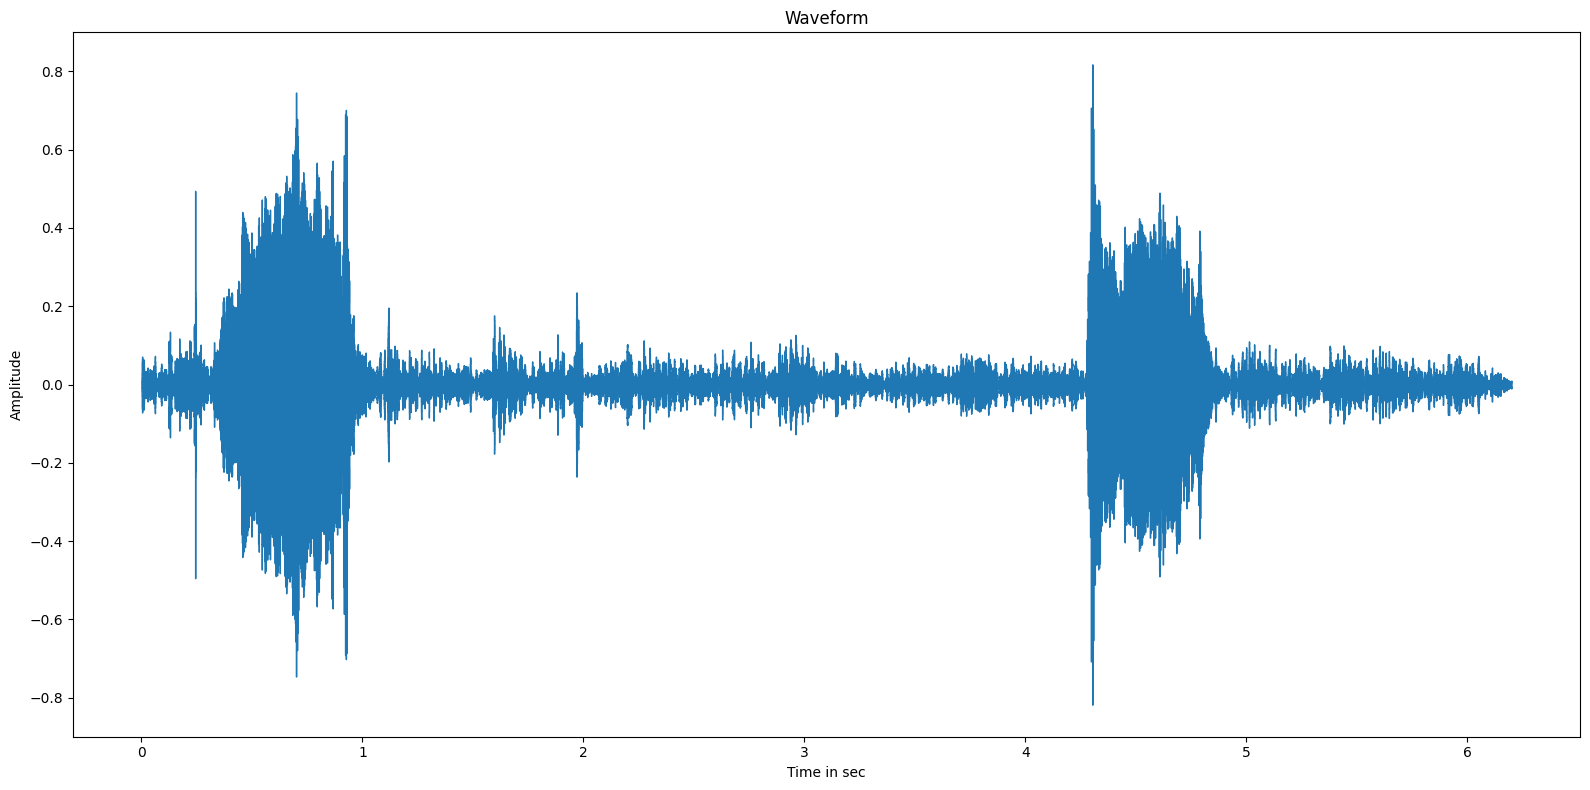

In [ ]:
import librosa.display

plt.figure(figsize=(16,8))
librosa.display.waveshow(y,sr = sr)
plt.title("Waveform")
plt.xlabel("Time in sec")
plt.ylabel("Amplitude")
plt.tight_layout()
plt.show()

# Observation 

Here Librosa converts the signal to mono, meaning the channel will alays be 1

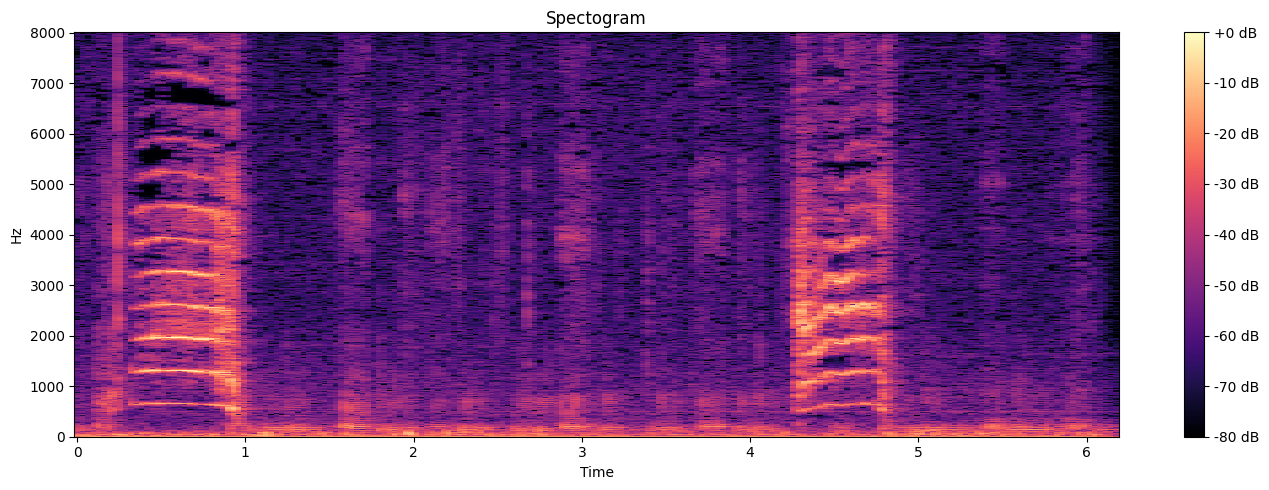

In [25]:
D = np.abs(librosa.stft(y))
DB = librosa.amplitude_to_db(D,ref =np.max ) # converting the amplitude to the decibals

plt.figure(figsize = (14,5))
librosa.display.specshow(DB, sr = sr,x_axis = 'time',y_axis = "hz")
plt.colorbar(format = "%+2.0f dB")
plt.title("Spectogram")
plt.tight_layout()
plt.show()

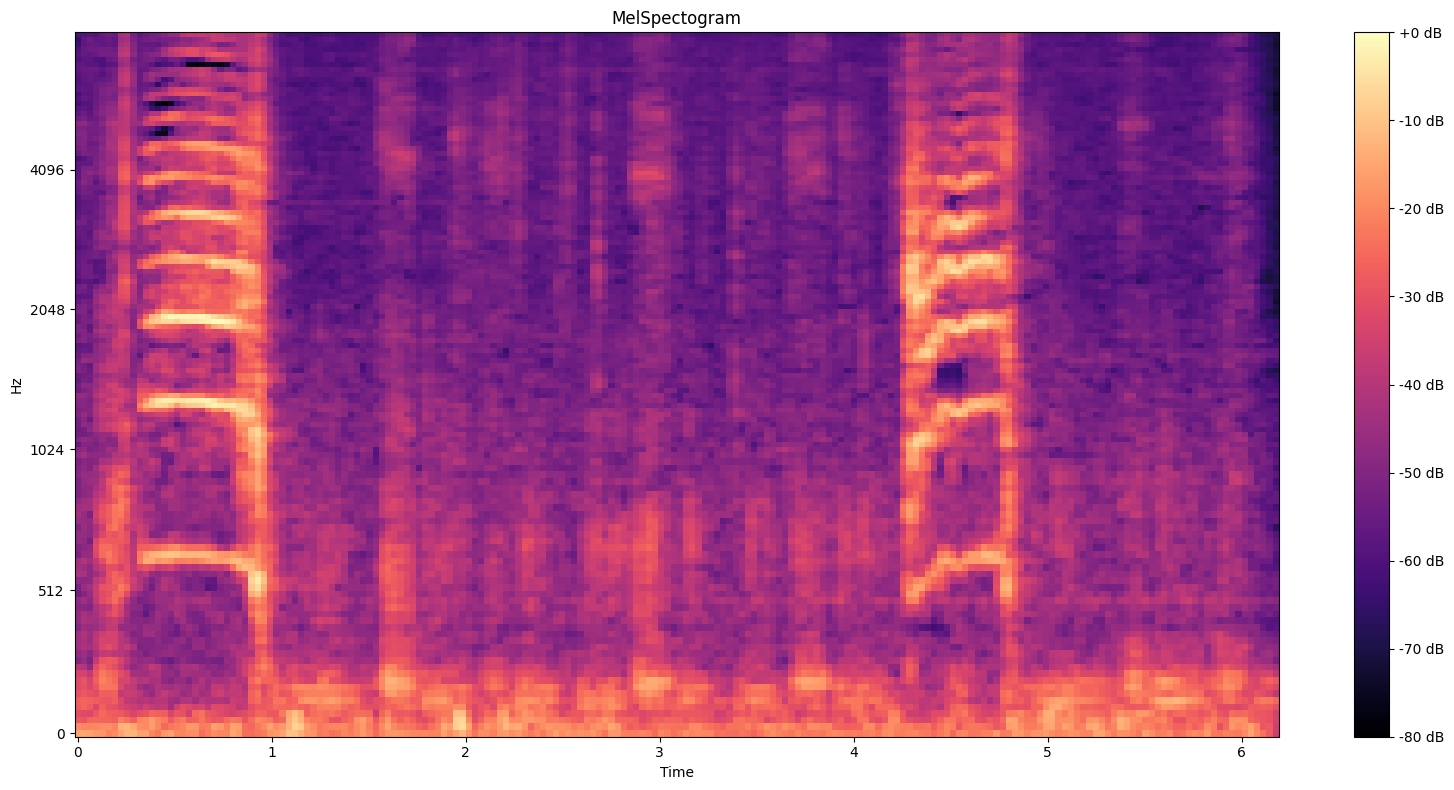

In [31]:
S = librosa.feature.melspectrogram(y = y,sr =sr,n_mels = 128)
S_DB = librosa.power_to_db(S,ref = np.max)

plt.figure(figsize=(16,8))
librosa.display.specshow(S_DB,sr = sr, x_axis = "time",y_axis = "mel")
plt.colorbar(format = "%+2.0f dB")
plt.title("MelSpectogram")
plt.tight_layout()
plt.show()

In [ ]:
S 

array([[8.9622297e+00, 9.9821177e+00, 8.4089947e+00, ..., 1.3095992e+00,
        4.9087989e-01, 8.1465930e-02],
       [3.6335607e+00, 2.6223371e+00, 2.7690191e+00, ..., 4.1724238e-01,
        4.6760744e-01, 1.0144035e-01],
       [4.6205592e-01, 3.5407579e-01, 7.5343686e-01, ..., 3.9457878e-01,
        3.1900313e-01, 1.2087859e-01],
       ...,
       [1.6288184e-04, 6.3375285e-04, 8.4112387e-04, ..., 5.8545524e-05,
        3.5477613e-05, 1.7835477e-05],
       [9.2028124e-05, 6.1801134e-04, 1.1036451e-03, ..., 6.7914472e-05,
        5.1498959e-05, 2.1143160e-05],
       [2.4715904e-04, 3.5187928e-04, 3.8841940e-04, ..., 4.3394190e-05,
        4.2903936e-05, 2.5964304e-05]], dtype=float32)

In [33]:
DB

array([[-23.121546, -18.59389 , -16.406815, ..., -23.466793, -23.516605,
        -30.678175],
       [-24.56356 , -25.19694 , -20.774809, ..., -24.388737, -27.68658 ,
        -35.19061 ],
       [-22.17977 , -19.37447 , -20.783588, ..., -27.245478, -37.803474,
        -50.367363],
       ...,
       [-65.845985, -79.98062 , -70.03597 , ..., -73.64752 , -72.91562 ,
        -70.68978 ],
       [-64.977455, -64.414375, -62.692085, ..., -71.23275 , -75.58058 ,
        -76.414734],
       [-64.58064 , -74.28845 , -61.144196, ..., -79.00501 , -80.      ,
        -80.      ]], dtype=float32)

In [34]:
S_DB

array([[-15.268808, -14.800742, -15.545528, ..., -23.621586, -27.883217,
        -35.68321 ],
       [-19.189644, -20.606083, -20.369709, ..., -28.589085, -28.094154,
        -34.73086 ],
       [-28.146023, -29.302006, -26.0225  , ..., -28.83163 , -29.75502 ,
        -33.969475],
       ...,
       [-62.674244, -56.77377 , -55.54437 , ..., -67.11803 , -69.29343 ,
        -72.28012 ],
       [-65.15376 , -56.883003, -54.364674, ..., -66.47334 , -67.67498 ,
        -71.54127 ],
       [-60.863205, -59.329033, -58.89996 , ..., -68.418655, -68.467995,
        -70.6492  ]], dtype=float32)

# now we will , check whether the our audio contain how many channel , and will draw it using the diffrent color

In [40]:
### Lets read with scipy
from scipy.io import wavfile as wav
wave_sample_rate, wave_audio = wav.read(file_path)
wave_audio

array([-249, -201, -122, ..., -196, -200, -176], dtype=int16)

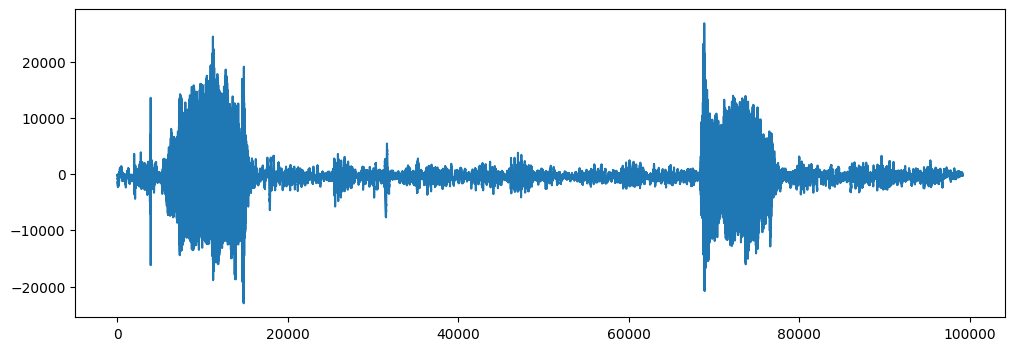

In [ ]:
# Original audio with 1 channels 
plt.figure(figsize=(12, 4))
plt.plot(wave_audio)

# Extract Features

Here we will be using Mel-Frequency Cepstral Coefficients(MFCC) from the audio samples. The MFCC summarises the frequency distribution across the window size, so it is possible to analyse both the frequency and time characteristics of the sound. These audio representations will allow us to identify features for classification

In [44]:
mfccs = librosa.feature.mfcc(y=y, sr= sr, n_mfcc=40)
print(mfccs.shape)
# as we know mfcc is a technique used to convert the audio into the features baesed on frequnecy and time charectersits , 
# and this will help in classification later


(40, 194)


In [46]:
mfccs

array([[-299.22903  , -274.5523   , -287.83896  , ..., -360.40472  ,
        -385.31934  , -415.0272   ],
       [  71.62544  ,   68.32066  ,   64.04074  , ...,   88.93592  ,
          96.024765 ,   99.44429  ],
       [  29.040096 ,   28.938251 ,   29.768621 , ...,   34.880028 ,
          40.982758 ,   34.085243 ],
       ...,
       [   3.4499984,    5.589713 ,    5.4401484, ...,    2.225021 ,
           7.7919965,    7.2040806],
       [   5.246185 ,    1.8460572,    2.5050385, ...,    2.8364646,
           3.2590427,   -1.131535 ],
       [   2.5456038,    3.0550647,    2.6050453, ...,   -1.8451391,
          -3.3491726,   -5.3866286]], dtype=float32)

In [84]:
# here we are doing the mfcc for all the traing data, as storing in the list, with label
dataset_path = "/Users/vinni/Desktop/Audio Classification Project/Audio Binary Classification/cats_dogs/train"


train_data = []

for label in ["cat", "dog"]:

    folder_path = os.path.join(dataset_path, label)

    for file in os.listdir(folder_path):

        file_path = os.path.join(folder_path, file)

        # Load audio
        y, sr = librosa.load(file_path, sr=22050)

        # Extract MFCC
        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=40
        )

        # Store MFCC and label
        train_data.append([mfcc, label])

print("Total audio files:", len(train_data))

Total audio files: 210


In [85]:
print("How its being represented")
print(train_data[0][0].shape) # as we can see the shaep of mfcc is 2-d so we gonna using the 
# CNN model , as convolutional layer will able to extract the feature precisely
# we can aslo use the Dense/ANN dl ALSO , but in this u have to flatten the mfcc, due to which we can lost some amount of data
print(train_data[0][1])

How its being represented
(40, 268)
cat


In [86]:
# now stroing the test data
# here we are doing the mfcc for all the traing data, as storing in the list, with label
dataset_path = "/Users/vinni/Desktop/Audio Classification Project/Audio Binary Classification/cats_dogs/test"


test_data = []

for label in ["cat", "dog"]:

    folder_path = os.path.join(dataset_path, label)

    for file in os.listdir(folder_path):

        file_path = os.path.join(folder_path, file)

        # Load audio
        y, sr = librosa.load(file_path, sr=22050)

        # Extract MFCC
        mfcc = librosa.feature.mfcc(
            y=y,
            sr=sr,
            n_mfcc=40
        )

        # Store MFCC and label
        test_data.append([mfcc, label])

print("Total audio files:", len(test_data))

Total audio files: 67


In [98]:
print("How its being represented")
print(test_data[0][0].shape)
print(test_data[0][1])

How its being represented
(40, 517)
cat


In [88]:
from collections import Counter

labels = [item[1] for item in train_data]

print(Counter(labels))

Counter({'cat': 125, 'dog': 85})


In [89]:
from collections import Counter

labels = [item[1] for item in test_data]

print(Counter(labels))

Counter({'cat': 39, 'dog': 28})


In [90]:
# before shuffling
for label in range(10):
    print(test_data[label][1])

cat
cat
cat
cat
cat
cat
cat
cat
cat
cat


In [94]:
# now doing the shuffing , in order to avoid baised learning
import random 
random.shuffle(train_data)

In [95]:
# after shuffling
for label in range(10):
    print(train_data[label][1])

dog
cat
dog
dog
cat
cat
cat
dog
dog
cat


# as the time frame of each data is not same, so we gona do tha padding overhere. as while giving the data to model, data should be uniform

In [99]:
# finding ht emax mfcc length
lengths = [item[0].shape[1] for item in train_data]

print("Minimum:", min(lengths))
print("Maximum:", max(lengths))
print("Mean:", np.mean(lengths))

Minimum: 41
Maximum: 762
Mean: 310.57142857142856


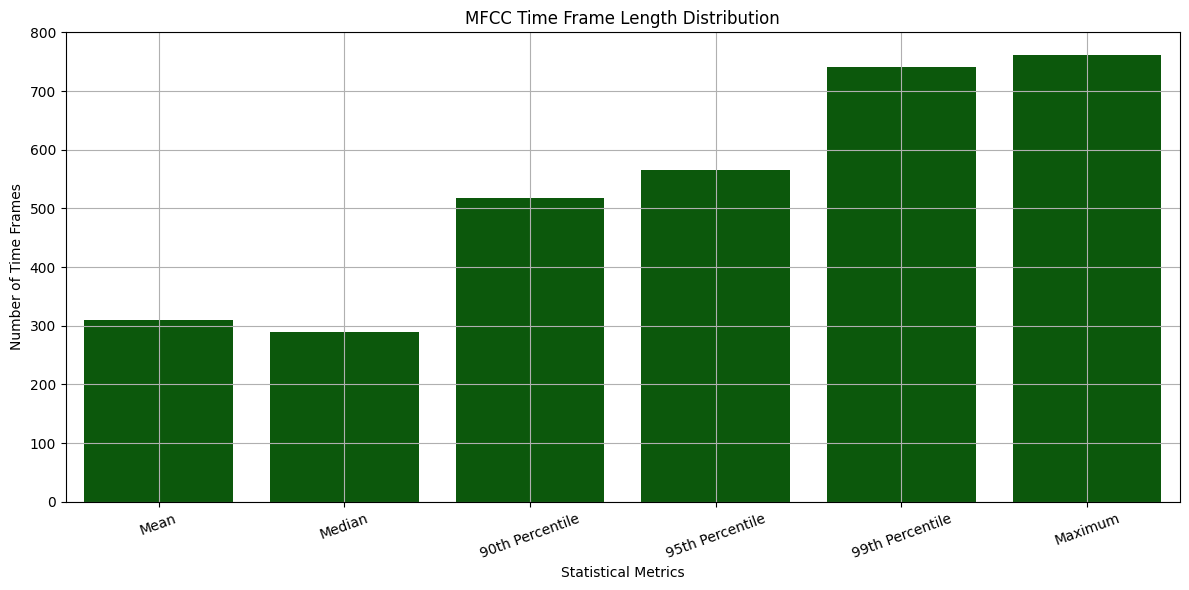

In [ ]:

lengths = np.array([
    item[0].shape[1] for item in train_data
])

mean = np.mean(lengths)
median = np.median(lengths)
percentile_90 = np.percentile(lengths, 90)
percentile_95 =  np.percentile(lengths, 95)
percentile_99 =  np.percentile(lengths, 99)



metrics = ["Mean", "Median", "90th Percentile",
           "95th Percentile", "99th Percentile", "Maximum"]

values = [mean, median, percentile_90, percentile_95, percentile_99, 762]

plt.figure(figsize=(12, 6))

sns.barplot(x=metrics, y=values, color="darkgreen")

plt.title("MFCC Time Frame Length Distribution")
plt.xlabel("Statistical Metrics")
plt.ylabel("Number of Time Frames")
plt.xticks(rotation=20)

plt.tight_layout()
plt.grid()
plt.show()


# now doing the padding/turncating time frame = 510

In [116]:
def fix_mfcc_length(mfcc, max_length=565):

    if mfcc.shape[1] < max_length:
        pad_width = max_length - mfcc.shape[1]

        mfcc = np.pad(
            mfcc,
            ((0, 0), (0, pad_width)),
            mode="constant"
        )

    else:
        mfcc = mfcc[:, :max_length]

    return mfcc

In [117]:
padded_train_data= [
    [fix_mfcc_length(mfcc, 565), label]
    for mfcc, label in train_data
]

In [118]:
padded_test_data= [
    [fix_mfcc_length(mfcc, 565), label]
    for mfcc, label in test_data
]

In [119]:
print("Before Padding time frame of train",train_data[0][0].shape)
print("Before Padding time frame of test",test_data[0][0].shape)
print("After Padding time frame of train",padded_train_data[0][0].shape)
print("After Padding time frame of test",padded_train_data[0][0].shape)


Before Padding time frame of train (40, 112)
Before Padding time frame of test (40, 517)
After Padding time frame of train (40, 565)
After Padding time frame of test (40, 565)


In [ ]:
from sklearn.preprocessing import LabelEncoder

# Separate features and labels
X_train = np.array([item[0] for item in padded_train_data])
y_train = np.array([item[1] for item in padded_train_data])

# Convert labels into integers
encoder = LabelEncoder()
y_train_encoded = encoder.fit_transform(y_train)


print("X_train shape:", X_train.shape)
print("y_train shape:", y_train_encoded.shape)
print("Classes:", encoder.classes_)

X_train shape: (210, 40, 565)
y_train shape: (210,)
Classes: ['cat' 'dog']


In [122]:
# y_test and x_test
X_test = np.array([item[0] for item in padded_test_data])
y_test = np.array([item[1] for item in padded_test_data])
y_test_encoded = encoder.fit_transform(y_test)

In [147]:
import numpy as np
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    BatchNormalization,
    ReLU,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Flatten,
    Dense,
    Dropout
)

# Add channel dimension --> as cnn expect width*height* channel ie RGB , here we are using the mfcc toh channel ek hi 
X_train_cnn = X_train[..., np.newaxis]

print("X_train shape:", X_train_cnn.shape)

X_train shape: (210, 40, 565, 1)


In [158]:
model = Sequential()


model.add(Input(shape=(40, 565, 1)))

# Convolutional Layer 1 
model.add(Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding="same"
))
model.add(BatchNormalization())
model.add(ReLU())



#Convolutional Layer 2
model.add(Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding="same"
))
model.add(BatchNormalization())
model.add(ReLU())



# Convolutional Layer 3
model.add(Conv2D(
    filters=128,
    kernel_size=(3, 3),
    padding="valid"
))
model.add(ReLU())
# Pooling after feature extraction
model.add(MaxPooling2D(pool_size=(2, 2)))


#Fully Connected Layers 

model.add(Flatten())

model.add(Dense(128, activation="relu"))

model.add(Dropout(0.5))

#Output Layer
model.add(Dense(1, activation="sigmoid"))

In [159]:
model.summary()

Model: "sequential_9"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_24 (Conv2D)              │ (None, 40, 565, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_16          │ (None, 40, 565, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_24 (ReLU)                 │ (None, 40, 565, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 40, 565, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_17          │ (None, 40, 565, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_25 (ReLU)                 │ (None, 40, 565, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 38, 563, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_26 (ReLU)                 │ (None, 38, 563, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 19, 281, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_5 (Flatten)             │ (None, 683392)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 128)            │    87,474,304 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 87,567,489 (334.04 MB)

 Trainable params: 87,567,297 (334.04 MB)

 Non-trainable params: 192 (768.00 B)

In [162]:
model.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [163]:
history = model.fit(X_train_cnn,y_train_encoded,validation_data=(X_test,y_test_encoded),batch_size=8,epochs=50)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 11s 347ms/step - accuracy: 0.7476 - loss: 5.9181 - val_accuracy: 0.8209 - val_loss: 0.3641
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 345ms/step - accuracy: 0.9000 - loss: 0.3626 - val_accuracy: 0.8657 - val_loss: 0.2862
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 357ms/step - accuracy: 0.9333 - loss: 0.2455 - val_accuracy: 0.8955 - val_loss: 0.2739
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 368ms/step - accuracy: 0.9524 - loss: 0.1501 - val_accuracy: 0.8507 - val_loss: 0.6523
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 372ms/step - accuracy: 0.9619 - loss: 0.0862 - val_accuracy: 0.8806 - val_loss: 0.3105
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 377ms/step - accuracy: 0.9810 - loss: 0.0548 - val_accuracy: 0.9104 - val_loss: 0.3139
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 379ms/step - accuracy: 0.9905 - loss: 0.0488 - val_accuracy: 0.9104 - val_loss: 0.3371
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 10s 370ms/step - accuracy: 0.9762 - loss: 0.0847 - val_accur

## now instead of using flatten layer, im using the globalavg polling layer, in order to reduce the training accuracy, as
becasue of more parameter it become overfitted

In [164]:
model_1 = Sequential()


model_1.add(Input(shape=(40, 565, 1)))

# Convolutional Layer 1 
model_1.add(Conv2D(
    filters=32,
    kernel_size=(3, 3),
    padding="same"
))
model_1.add(BatchNormalization())
model_1.add(ReLU())

#Convolutional Layer 2
model_1.add(Conv2D(
    filters=64,
    kernel_size=(3, 3),
    padding="same"
))
model_1.add(BatchNormalization())
model_1.add(ReLU())

# Convolutional Layer 3
model_1.add(Conv2D(
    filters=128,
    kernel_size=(3, 3),
    padding="valid"
))
model_1.add(ReLU())

# Pooling after feature extraction
model_1.add(MaxPooling2D(pool_size=(2, 2)))

# Instead of Flatten
model_1.add(GlobalAveragePooling2D())
model_1.add(Dense(128, activation="relu"))

model_1.add(Dropout(0.5))
#Output Layer
model_1.add(Dense(1, activation="sigmoid"))

In [165]:
model_1.summary()

Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_30 (Conv2D)              │ (None, 40, 565, 32)    │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_20          │ (None, 40, 565, 32)    │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_30 (ReLU)                 │ (None, 40, 565, 32)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_31 (Conv2D)              │ (None, 40, 565, 64)    │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_21          │ (None, 40, 565, 64)    │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_31 (ReLU)                 │ (None, 40, 565, 64)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_32 (Conv2D)              │ (None, 38, 563, 128)   │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_32 (ReLU)                 │ (None, 38, 563, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 19, 281, 128)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_4      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_20 (Dense)                │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_21 (Dense)                │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,697 (428.50 KB)

 Trainable params: 109,505 (427.75 KB)

 Non-trainable params: 192 (768.00 B)

In [166]:
model_1.compile(
    loss="binary_crossentropy",
    optimizer="adam",
    metrics=["accuracy"]
)

In [167]:
history_1= model_1.fit(X_train_cnn,y_train_encoded,validation_data=(X_test,y_test_encoded),batch_size=8,epochs=50)

Epoch 1/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 279ms/step - accuracy: 0.6190 - loss: 0.6502 - val_accuracy: 0.5821 - val_loss: 0.6732
Epoch 2/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 282ms/step - accuracy: 0.7143 - loss: 0.5372 - val_accuracy: 0.7910 - val_loss: 0.5060
Epoch 3/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 274ms/step - accuracy: 0.7429 - loss: 0.4920 - val_accuracy: 0.8060 - val_loss: 0.4495
Epoch 4/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 273ms/step - accuracy: 0.7952 - loss: 0.4925 - val_accuracy: 0.8358 - val_loss: 0.4496
Epoch 5/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 275ms/step - accuracy: 0.8048 - loss: 0.4820 - val_accuracy: 0.8209 - val_loss: 0.4160
Epoch 6/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 277ms/step - accuracy: 0.8381 - loss: 0.4474 - val_accuracy: 0.8060 - val_loss: 0.4019
Epoch 7/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 278ms/step - accuracy: 0.8333 - loss: 0.4941 - val_accuracy: 0.7910 - val_loss: 0.4037
Epoch 8/50
27/27 ━━━━━━━━━━━━━━━━━━━━ 8s 282ms/step - accuracy: 0.8619 - loss: 0.4165 - val_accuracy: 0.

# visualizing the model(flatten layer) 

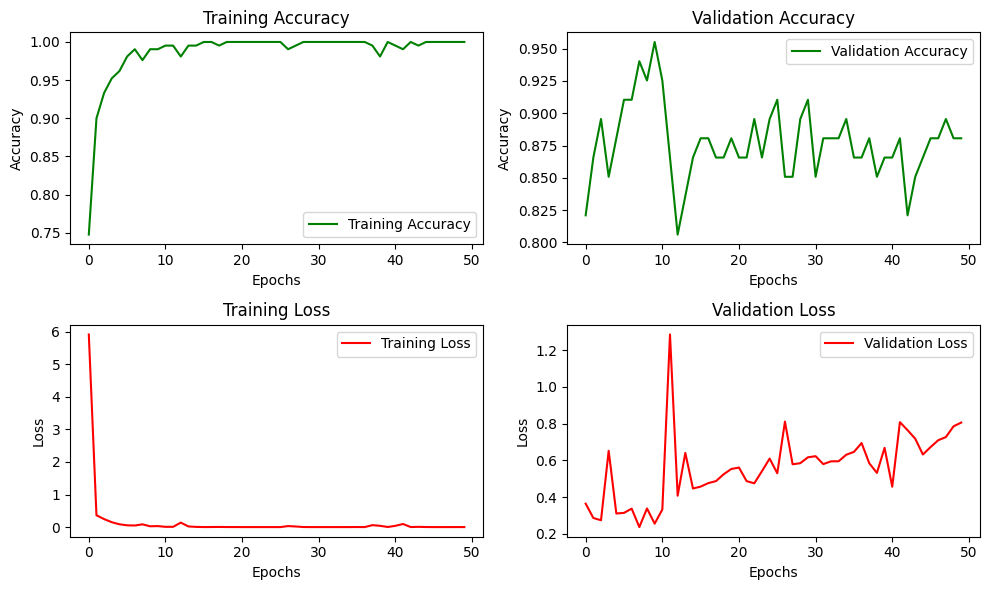

In [180]:
training_acc = history.history["accuracy"]
training_loss = history.history["loss"]

validation_acc = history.history["val_accuracy"]
validation_loss = history.history["val_loss"]

plt.figure(figsize=(10, 6))

# Training Accuracy
plt.subplot(2, 2, 1)
plt.plot(training_acc, label="Training Accuracy",color = "green")
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Validation Accuracy
plt.subplot(2, 2, 2)
plt.plot(validation_acc, label="Validation Accuracy",color ="green")
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Training Loss
plt.subplot(2, 2, 3)
plt.plot(training_loss, label="Training Loss",color ="red")
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Validation Loss
plt.subplot(2, 2, 4)
plt.plot(validation_loss, label="Validation Loss",color ="red")
plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()

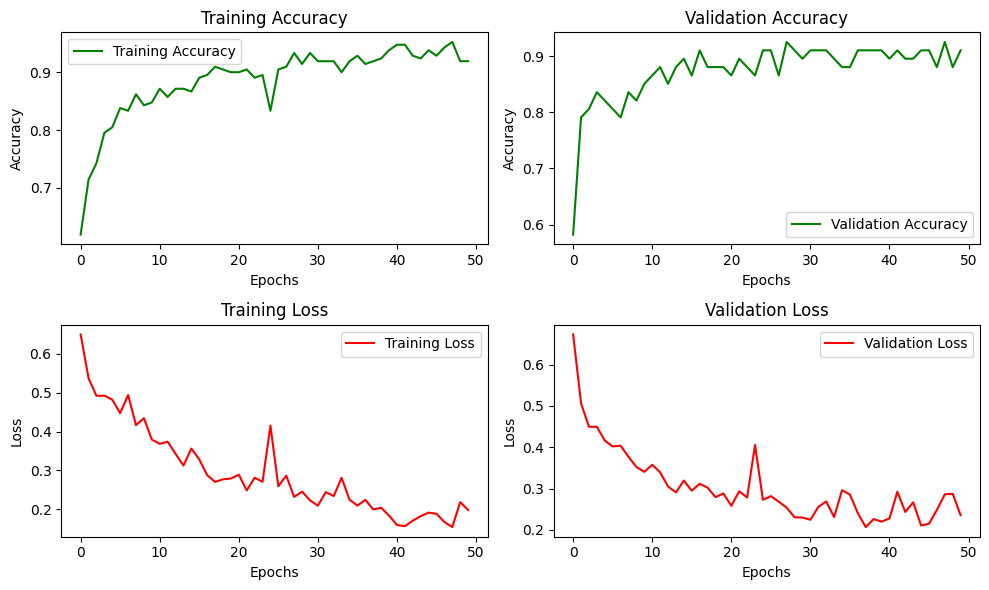

In [181]:
training_acc = history_1.history["accuracy"]
training_loss = history_1.history["loss"]

validation_acc = history_1.history["val_accuracy"]
validation_loss = history_1.history["val_loss"]

plt.figure(figsize=(10, 6))

# Training Accuracy
plt.subplot(2, 2, 1)
plt.plot(training_acc, label="Training Accuracy",color = "green")
plt.title("Training Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Validation Accuracy
plt.subplot(2, 2, 2)
plt.plot(validation_acc, label="Validation Accuracy",color = "green")
plt.title("Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()

# Training Loss
plt.subplot(2, 2, 3)
plt.plot(training_loss, label="Training Loss",color ="red")
plt.title("Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

# Validation Loss
plt.subplot(2, 2, 4)
plt.plot(validation_loss, label="Validation Loss",color ="red")
plt.title("Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()

plt.tight_layout()
plt.show()